# 현실의 데이터 26: 3D 포인트 클라우드

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/26_point_cloud.ipynb)

**분야**: 이미지 · 소리 · 3D &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 3D 비전 · LiDAR · 점 구름 · 물체 인식

> 점 2,048개만 보고 의자인지 비행기인지 맞힐 수 있을까?

**데이터**: ModelNet40 (점 2,048개 판, 시험 묶음 2,468개) (약 60MB). Princeton (Wu et al., 2015). CAD 물체 40종류의 표면에서 점 2,048개를 뽑은 판 (Hugging Face jxie/modelnet40-2048). 여기서는 시험 묶음 2,468개만 받아 다시 나눈다.

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 물체 하나 (점 2,048개 × x, y, z) |
| ② 입력 X | 점 구름에서 뽑은 모양 숫자 (퍼진 방향 · 크기 · 거리 분포) |
| ③ 출력 y | 40종류 중 무엇 |
| ④ 평가지표 | 정확도 |
| ⑤ 기준선 | 가장 흔한 종류 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Wu et al. (2015) 3D ShapeNets: A Deep Representation for Volumetric Shapes, CVPR](https://arxiv.org/abs/1406.5670)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

In [2]:
URL = "https://huggingface.co/api/datasets/jxie/modelnet40-2048/parquet/default/test/0.parquet"
df = pd.read_parquet(download(URL, "data/modelnet40_test.parquet"))
NAMES = ["airplane", "bathtub", "bed", "bench", "bookshelf", "bottle", "bowl", "car", "chair", "cone", "cup", "curtain", "desk", "door",
         "dresser", "flower_pot", "glass_box", "guitar", "keyboard", "lamp", "laptop", "mantel", "monitor", "night_stand", "person", "piano",
         "plant", "radio", "range_hood", "sink", "sofa", "stairs", "stool", "table", "tent", "toilet", "tv_stand", "vase", "wardrobe", "xbox"]
points = np.stack([np.stack(p) for p in df["inputs"]]).astype(np.float32)      # (objects, 2048, 3)
labels = df["label"].values
print(points.shape, "classes:", len(np.unique(labels)))
print(pd.Series([NAMES[i] for i in labels]).value_counts().head(8))

(2468, 2048, 3) classes: 40
range_hood    100
airplane      100
plant         100
tv_stand      100
bookshelf     100
piano         100
vase          100
glass_box     100
Name: count, dtype: int64


## 열어 보기: 점 구름을 3D 로

점 2,048개가 물체의 겉면 모양을 이룬다. 몇 개를 그려 보자.

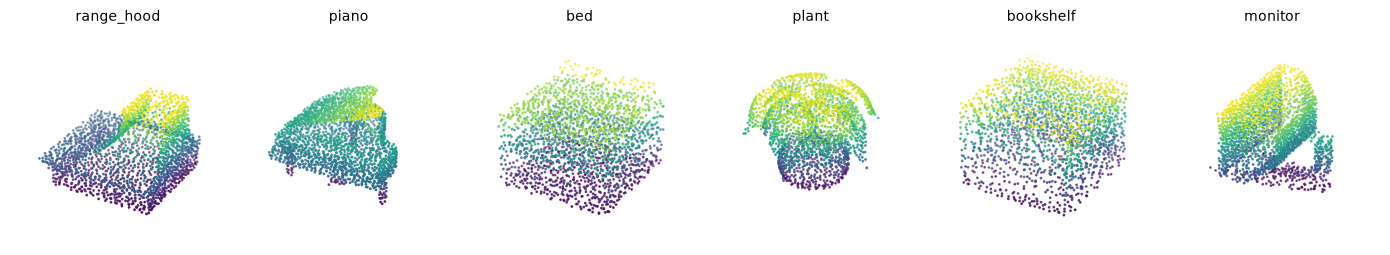

In [3]:
fig = plt.figure(figsize=(14, 3.2))
for k, i in enumerate([0, 300, 700, 1100, 1500, 2000]):
    ax = fig.add_subplot(1, 6, k + 1, projection="3d")
    p = points[i]; ax.scatter(p[:, 0], p[:, 2], p[:, 1], s=1, c=p[:, 1], cmap="viridis")
    ax.set_title(NAMES[labels[i]], fontsize=10); ax.set_axis_off()
plt.tight_layout(); plt.show()

## 문제 하나 골라 보기: 점 구름 → 종류 (40가지)

점의 순서는 의미가 없다 (같은 물체도 점 순서는 마음대로). 그래서 **순서와 상관없는 숫자** 를 뽑는다:
- 가운데로 옮기고 크기를 맞춘 뒤 (1주 3차시 '정규화'), 퍼진 방향 3개의 크기 (공분산 고윳값)
- 가로 · 세로 · 높이 길이
- 점 두 개 사이 거리의 분포 (D2 모양 분포), 중심에서의 거리 분포

그리고 랜덤 포레스트. 기준선 = 가장 흔한 종류.

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

def shape_features(p, rng):
    """Order-free numbers describing one point cloud (2048 x 3)"""
    p = p - p.mean(0); p = p / np.abs(p).max()
    eig = np.sort(np.linalg.eigvalsh(np.cov(p.T)))[::-1]
    ext = np.sort(p.max(0) - p.min(0))[::-1]
    i, j = rng.integers(0, len(p), (2, 3000))
    d2 = np.histogram(np.linalg.norm(p[i] - p[j], axis=1), bins=16, range=(0, 2), density=True)[0]
    rad = np.histogram(np.linalg.norm(p, axis=1), bins=16, range=(0, 1.8), density=True)[0]
    hgt = np.histogram(p[:, 1], bins=8, range=(-1, 1), density=True)[0]
    return np.r_[eig / eig.sum(), ext, d2, rad, hgt]

rng = np.random.default_rng(0)
X = np.stack([shape_features(p, rng) for p in points])
Xtr, Xte, ytr, yte = train_test_split(X, labels, test_size=0.3, stratify=labels, random_state=0)
m = RandomForestClassifier(500, random_state=0, n_jobs=-1).fit(Xtr, ytr)
pred = m.predict(Xte)
most = np.bincount(ytr).argmax()
print(f"baseline (always {NAMES[most]}): accuracy {np.mean(yte == most):.1%}")
print(f"random forest on shape numbers : accuracy {np.mean(yte == pred):.1%}")
per = pd.Series(yte == pred).groupby([NAMES[i] for i in yte]).mean().sort_values()
print("hardest:", per.head(5).round(2).to_dict())
print("easiest:", per.tail(5).round(2).to_dict())

baseline (always airplane): accuracy 4.0%
random forest on shape numbers : accuracy 71.9%
hardest: {'xbox': 0.0, 'stairs': 0.0, 'flower_pot': 0.0, 'cup': 0.0, 'tent': 0.17}
easiest: {'guitar': 0.97, 'table': 0.97, 'car': 0.97, 'laptop': 1.0, 'keyboard': 1.0}


**관찰**: 손으로 만든 모양 숫자만으로도 72% 쯤 맞힌다. 기타 · 자동차 · 노트북처럼 모양이 뚜렷한 것은 거의 다 맞히고, xbox · 컵 · 계단처럼 **데이터가 20개뿐인 종류** 는 거의 못 맞힌다. 종류마다 데이터 수가 다르면 정확도 하나로는 이런 차이가 가려진다. 점 구름을 그대로 받는 신경망 (PointNet 등) 은 90% 안팎까지 간다.

## 다른 문제로 바꿔 보기

- **자율주행 · 로봇의 LiDAR**: 한 행이 '물체 하나' 가 아니라 '장면 전체 (수십만 점)' 가 되면, 출력은 '점마다 무엇인가 (분할)' 나 '물체마다 상자 (검출)' 가 된다.
- 점을 2,048개가 아니라 256개만 쓰면? 센서가 싸질수록 점이 줄어든다.

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |